# Tahap 5 — Klasifikasi dengan CNN Ringan (*Deep Learning*)

Tahap **Classification** dan **Evaluation** pada pipeline slide 10, kini dengan *convolutional neural network*
yang membaca representasi waktu–frekuensi 2D secara langsung (bukan vektor statistik seperti Tahap 4).
Model dilatih oleh `scripts/05_train_cnn.py` (logika di `src/models_cnn.py`, metrik di `src/evaluate.py` yang sama
dengan ML klasik); notebook ini hanya memuat hasil dan menampilkan grafik.

**Input.** Log-mel spectrogram (64 pita mel) dan MFCC 2D (40 koefisien), 10 s, hop 10 ms (Tahap 3).
Untuk menghemat komputasi CPU, tiap 2 frame dirata-rata → resolusi waktu **20 ms** (500 frame); batuk
berlangsung ±200–500 ms sehingga detail temporal masih terjaga.

**Protokol (anti-*leakage*, sebanding dengan Tahap 4)**
1. Normalisasi per pita frekuensi (mean/std) di-*fit* pada **train** saja.
2. Augmentasi **hanya pada train**, *on-the-fly*: *random crop* 256 frame (5,12 s) dengan offset acak di dalam
   area berisi suara, *random time shift* ±20 frame (±0,4 s), dan **SpecAugment** (2 *frequency mask* ≤ 8 pita
   [MFCC: ≤ 5] + 2 *time mask* ≤ 25 frame). Val/test: rekaman penuh 10 s tanpa augmentasi — *Global Average
   Pooling* membuat CNN menerima panjang berapa pun.
3. *Imbalance*: `BCEWithLogitsLoss(pos_weight = n_healthy/n_COVID = 3,0)` — **bukan** `WeightedRandomSampler`,
   karena train sudah di-*undersample* 3:1 (Tahap 2), sampler akan mengulang ±500 rekaman COVID ±3× per epoch
   (risiko hafalan), sedangkan `pos_weight` deterministik, setiap rekaman dilihat sekali per epoch, dan setara
   dengan `class_weight='balanced'` pada ML klasik.
4. AdamW (lr 10⁻³, *weight decay* 10⁻²), ReduceLROnPlateau pada AUC val (faktor 0,5, *patience* 4), maks 100 epoch,
   *early stopping* pada AUC val (*patience* 10) → checkpoint terbaik.
5. Ambang keputusan **Youden** dipilih di **val**; **test** dievaluasi sekali. Diulang dengan seed 42, 7, 2024
   → mean ± std. Baris utama di `hasil_semua_model.csv` = seed 42 (ditetapkan sebelum melihat hasil).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import display
from src.config import load_config, set_seed
from src import evaluate as ev, models_cnn as mc
from src.plots import (setup_style, save_fig, save_table, plot_roc_pr_all, plot_confusion, plot_training_curves,
                       plot_gradcam_grid, plot_arch_diagram, WARNA_MODEL, WARNA_SEED)

cfg = load_config(); set_seed(); setup_style()
pd.set_option('display.precision', 3); pd.set_option('display.width', 160)
M, LOG, TAB = cfg.paths.models, cfg.paths.logs, cfg.paths.tables
FITUR = {'logmel': 'log-mel', 'mfcc2d': 'MFCC 2D'}
SEEDS = [42, 7, 2024]
ckpt_path = lambda f, s: M / (f'cnn_{f}_A.pt' if s == 42 else f'cnn_{f}_A_seed{s}.pt')
CK = {(f, s): torch.load(ckpt_path(f, s), map_location='cpu', weights_only=False) for f in FITUR for s in SEEDS}
summary = json.loads((LOG / 'train_cnn_A_summary.json').read_text(encoding='utf-8'))
print('checkpoint dimuat:', len(CK), '| torch', torch.__version__, '| device saat training:', mc.get_device())

checkpoint dimuat: 6 | torch 2.15.0+cpu | device saat training: cpu


## 1. Arsitektur `LightCNN`

Terinspirasi R3 (Kranthi Kumar & Alphonse, 2022): blok **[Conv2d → BatchNorm → ReLU → MaxPool 2×2 → Dropout]**
dengan filter 16-32-64-128, lalu *Global Average Pooling* (GAP) dan satu neuron keluaran (logit → sigmoid =
P(COVID-19)). Dropout naik bertahap 0,10 → 0,20 antar-blok, 0,30 sebelum FC. Conv tanpa bias karena diikuti BN.
GAP membuat jumlah parameter **tidak bergantung** pada ukuran input → model log-mel (64 pita) dan MFCC (40 koef.)
punya parameter sama. Varian kernel **1×12** (R3: *receptive field* sempit di frekuensi, lebar di waktu = 240 ms)
disediakan sebagai parameter `--kernel 1x12`.

In [2]:
model = mc.build_model(CK[('logmel', 42)]['config'])
tab = mc.layer_table(model, (1, 1, 64, 256))
tab['output'] = tab['output'].map(lambda t: '×'.join(map(str, t)))
save_table(tab, '05_arsitektur_lightcnn', index=False)
display(tab)

var = {'LightCNN 4 blok, 3×3 (dipakai)': dict(arch='LightCNN'),
       'LightCNN 4 blok, 1×12 (ala R3)': dict(arch='LightCNN', kernel='1x12'),
       'LightCNN 5 blok, 3×3': dict(arch='LightCNN', n_blocks=5),
       'CRNN (3 blok CNN + BiGRU 64), log-mel': dict(arch='CRNN', n_freq=64)}
par = pd.DataFrame({'model': list(var), 'parameter': [mc.count_params(mc.build_model(c)) for c in var.values()]})
save_table(par, '05_jumlah_parameter', index=False)
display(par)
print('Pembanding: SVM RBF Tahap 4 menyimpan', end=' ')
import joblib; svm = joblib.load(M / 'ml_svm_A.joblib')['pipeline'][-1]
print(f'{svm.support_vectors_.shape[0]} support vector × {svm.support_vectors_.shape[1]} fitur')

,layer,tipe,output,parameter
0,features.0.0,Conv2d,16×64×256,144
1,features.0.1,BatchNorm2d,16×64×256,32
2,features.0.2,ReLU,16×64×256,0
3,features.0.3,MaxPool2d,16×32×128,0
4,features.0.4,Dropout,16×32×128,0
5,features.1.0,Conv2d,32×32×128,4608
6,features.1.1,BatchNorm2d,32×32×128,64
7,features.1.2,ReLU,32×32×128,0
8,features.1.3,MaxPool2d,32×16×64,0
9,features.1.4,Dropout,32×16×64,0


,model,parameter
0,"LightCNN 4 blok, 3×3 (dipakai)",97521
1,"LightCNN 4 blok, 1×12 (ala R3)",129825
2,"LightCNN 5 blok, 3×3",245233
3,"CRNN (3 blok CNN + BiGRU 64), log-mel",245489


Pembanding: SVM RBF Tahap 4 menyimpan 

1839 support vector × 315 fitur


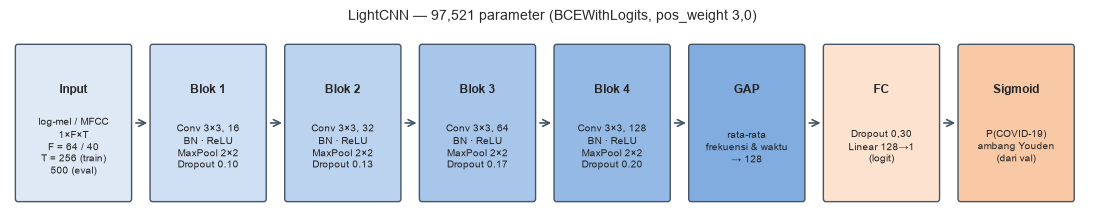

In [3]:
blocks = [('Input', 'log-mel / MFCC\n1×F×T\nF = 64 / 40\nT = 256 (train)\n500 (eval)'),
          *[(f'Blok {i+1}', f'Conv 3×3, {c}\nBN · ReLU\nMaxPool 2×2\nDropout {d:.2f}')
            for i, (c, d) in enumerate(zip([16, 32, 64, 128], [0.10, 0.133, 0.167, 0.20]))],
          ('GAP', 'rata-rata\nfrekuensi & waktu\n→ 128'),
          ('FC', 'Dropout 0,30\nLinear 128→1\n(logit)'),
          ('Sigmoid', 'P(COVID-19)\nambang Youden\n(dari val)')]
fig = plot_arch_diagram(blocks, f'LightCNN — {mc.count_params(model):,} parameter (BCEWithLogits, pos_weight 3,0)')
save_fig(fig, '05_arsitektur'); plt.show()

## 2. Augmentasi data (hanya train)
Contoh satu rekaman train setelah standardisasi per pita: asli (10 s, termasuk *padding*) dan tiga hasil augmentasi
acak (crop 5,12 s + geser + SpecAugment). Garis hijau = akhir area berisi suara (setelahnya *padding* nol).

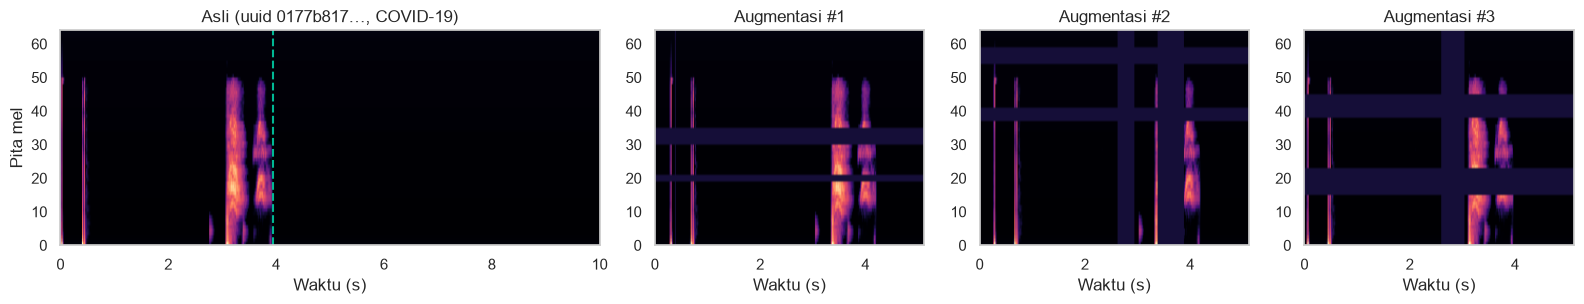

In [4]:
uu = np.load(cfg.paths.features / 'uuids_A_train.npy', allow_pickle=True)
yy = np.load(cfg.paths.features / 'labels_A_train.npy')
i_ex = int(np.flatnonzero(yy == 1)[3])
X1, y1, u1, L1 = mc.load_split('logmel', 'A', 'train', 2, [i_ex])
nrm = CK[('logmel', 42)]['normalizer']
X1 = ((X1.astype(np.float32) - nrm['mean']) / nrm['std'])
ds = mc.SpecDataset(X1, y1, L1, train=True, crop=256, seed=0)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), gridspec_kw={'width_ratios': [2, 1, 1, 1]})
axes[0].imshow(X1[0], origin='lower', aspect='auto', cmap='magma', extent=[0, 10, 0, 64])
axes[0].axvline(L1[0] * 0.02, color='#00b894', ls='--', lw=1.5)
axes[0].set(title=f'Asli (uuid {u1[0][:8]}…, COVID-19)', xlabel='Waktu (s)', ylabel='Pita mel')
for k, ax in enumerate(axes[1:]):
    xa = ds[0][0][0].numpy()
    ax.imshow(xa, origin='lower', aspect='auto', cmap='magma', extent=[0, xa.shape[1] * 0.02, 0, 64])
    ax.set(title=f'Augmentasi #{k+1}', xlabel='Waktu (s)')
for ax in axes: ax.grid(False)
fig.tight_layout(); save_fig(fig, '05_augmentasi'); plt.show()

## 3. Kurva *training*: loss & AUC per epoch
Garis putus-putus = train (dihitung *on-the-fly* pada potongan teraugmentasi dengan dropout aktif, jadi bukan
estimasi yang bersih), garis utuh = val (rekaman penuh). Titik = epoch dengan AUC val tertinggi (checkpoint).

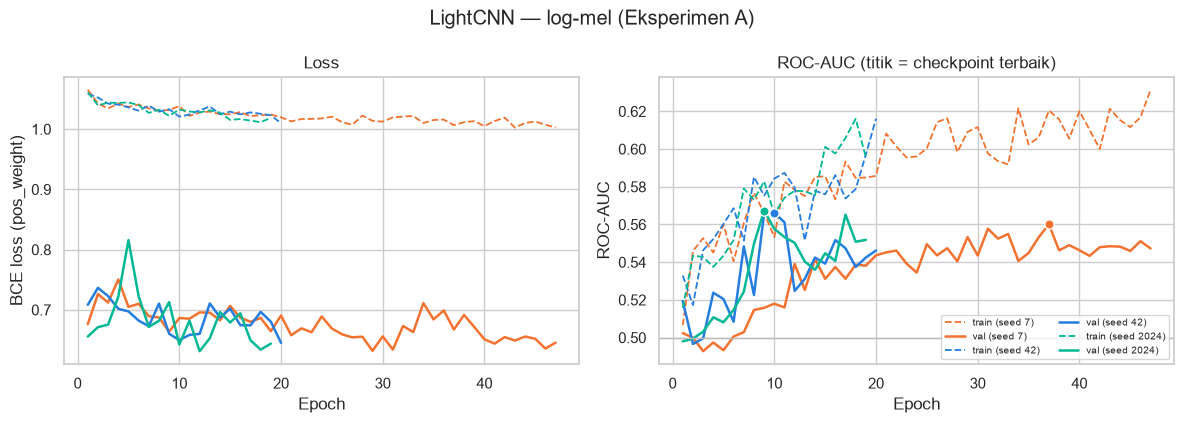

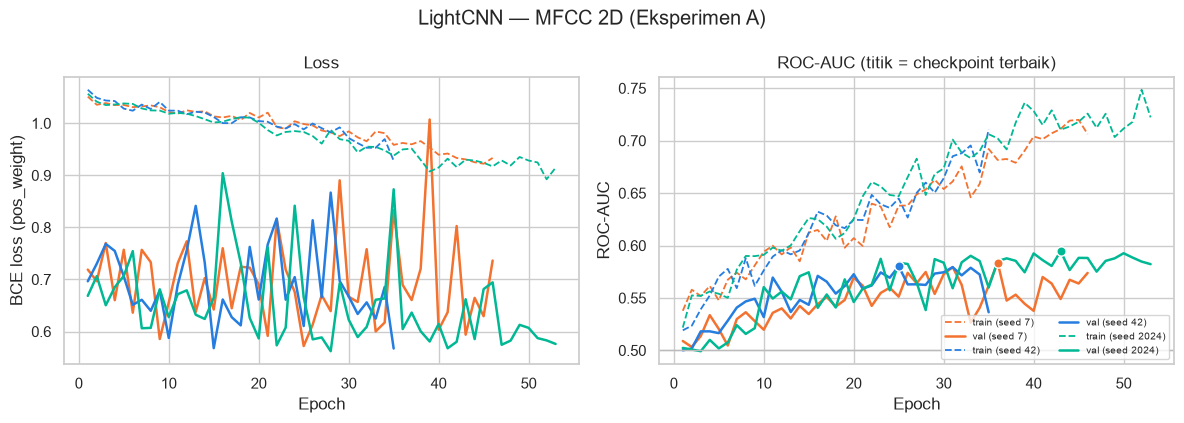

In [5]:
HIST = {}
for f, nama in FITUR.items():
    HIST[f] = pd.read_csv(LOG / f'cnn_{f}_history.csv')
    fig = plot_training_curves(HIST[f], f'LightCNN — {nama} (Eksperimen A)')
    save_fig(fig, f'05_kurva_training_{f}'); plt.show()

In [6]:
rows = []
for (f, s), ck in CK.items():
    h = HIST[f][HIST[f].seed == s].reset_index(drop=True)
    b = h.loc[h.val_auc.idxmax()]
    rows.append({'fitur': FITUR[f], 'seed': s, 'epoch_terbaik': int(b.epoch), 'epoch_total': int(h.epoch.max()),
                 'auc_train_terbaik': b.train_auc, 'auc_val_terbaik': b.val_auc,
                 'selisih_train_val': b.train_auc - b.val_auc,
                 'auc_train_akhir': h.train_auc.iloc[-1], 'auc_val_akhir': h.val_auc.iloc[-1],
                 'epoch_val_loss_min': int(h.loc[h.val_loss.idxmin(), 'epoch']),
                 'menit': ck['summary']['train_time_s'] / 60})
ovf = pd.DataFrame(rows)
save_table(ovf, '05_overfitting', index=False)
display(ovf)

,fitur,seed,epoch_terbaik,epoch_total,auc_train_terbaik,auc_val_terbaik,selisih_train_val,auc_train_akhir,auc_val_akhir,epoch_val_loss_min,menit
0,log-mel,42,10,20,0.584,0.566,0.018,0.616,0.546,20,8.598
1,log-mel,7,37,47,0.620,0.560,0.060,0.631,0.547,29,20.290
2,log-mel,2024,9,19,0.583,0.567,0.016,0.596,0.552,12,8.133
3,MFCC 2D,42,25,35,0.645,0.580,0.065,0.711,0.536,35,9.243
4,MFCC 2D,7,36,46,0.682,0.584,0.098,0.706,0.574,25,10.878
5,MFCC 2D,2024,43,53,0.710,0.595,0.116,0.722,0.582,28,14.142


## 4. Hasil per seed dan perbandingan log-mel vs MFCC 2D
Metrik TEST dengan ambang Youden dari val (sumber: `reports/tables/05_cnn_per_seed.csv`).

In [7]:
ps = pd.read_csv(TAB / '05_cnn_per_seed.csv')
ps = ps[ps.split == 'test'].copy()
ps['fitur'] = ps.model.str.extract(r'\((.*)\)')[0]
kol = ['model', 'seed', 'best_epoch', 'n_epochs', 'train_time_s', 'val_auc', 'roc_auc', 'roc_auc_ci_low',
       'roc_auc_ci_high', 'pr_auc', 'threshold', 'recall_sensitivity', 'specificity', 'precision', 'f1']
display(ps[kol].sort_values(['model']))

agg = ps.groupby('fitur').agg(val_auc_mean=('val_auc', 'mean'), val_auc_std=('val_auc', 'std'),
                              test_auc_mean=('roc_auc', 'mean'), test_auc_std=('roc_auc', 'std'),
                              pr_auc_mean=('pr_auc', 'mean'), pr_auc_std=('pr_auc', 'std'),
                              sens_mean=('recall_sensitivity', 'mean'), spes_mean=('specificity', 'mean'),
                              epoch_terbaik_mean=('best_epoch', 'mean'), menit_mean=('train_time_s', lambda x: x.mean() / 60))
# ensemble 3 seed (rata-rata probabilitas) — informasi tambahan, bukan model utama
pc = pd.read_parquet(M / 'preds_cnn_A.parquet')
for f, nama in FITUR.items():
    for sp in ['val', 'test']:
        d = pc[pc.split == sp]
        agg.loc[nama, f'ensemble3_{sp}_auc'] = ev.roc_auc_score(d.label, d[[f'cnn_{f}_s{s}' for s in SEEDS]].mean(1))
save_table(agg.reset_index(), '05_cnn_ringkasan', index=False)
display(agg)

,model,seed,best_epoch,n_epochs,train_time_s,val_auc,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,threshold,recall_sensitivity,specificity,precision,f1
10,CNN (MFCC 2D) s2024,2024,43,53,848.5,0.595,0.601,0.548,0.652,0.091,0.365,0.667,0.463,0.081,0.145
6,CNN (MFCC 2D) s42,42,25,35,554.6,0.580,0.544,0.487,0.601,0.086,0.362,0.463,0.596,0.076,0.130
8,CNN (MFCC 2D) s7,7,36,46,652.7,0.584,0.591,0.539,0.641,0.088,0.418,0.583,0.563,0.087,0.151
4,CNN (log-mel) s2024,2024,9,19,488.0,0.567,0.570,0.511,0.625,0.082,0.473,0.352,0.776,0.101,0.156
0,CNN (log-mel) s42,42,10,20,515.9,0.566,0.567,0.511,0.619,0.081,0.407,0.370,0.708,0.083,0.136
2,CNN (log-mel) s7,7,37,47,1217.4,0.560,0.579,0.525,0.631,0.083,0.393,0.657,0.435,0.077,0.137


,val_auc_mean,val_auc_std,test_auc_mean,test_auc_std,pr_auc_mean,pr_auc_std,sens_mean,spes_mean,epoch_terbaik_mean,menit_mean,ensemble3_val_auc,ensemble3_test_auc
fitur,,,,,,,,,,,,
MFCC 2D,0.586,0.007,0.579,0.030,0.088,2.681e-03,0.571,0.541,34.667,11.421,0.596,0.591
log-mel,0.565,0.004,0.572,0.006,0.082,9.467e-04,0.460,0.640,18.667,12.341,0.568,0.576


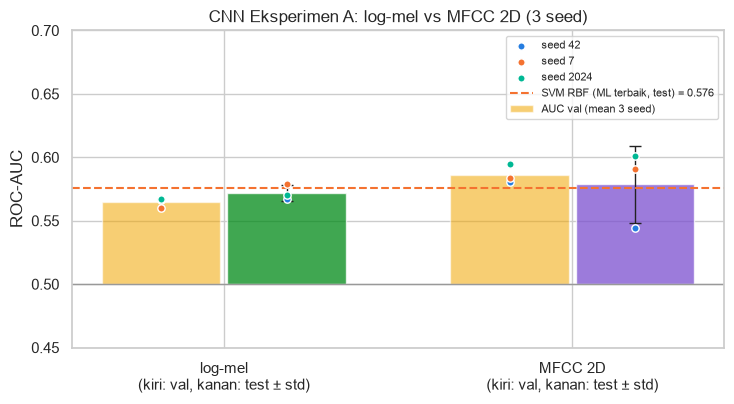

In [8]:
res = ev.load_results('A')
ml = res[(res.split == 'test') & ~res.model.str.startswith('CNN')].set_index('model')
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for j, (f, nama) in enumerate(FITUR.items()):
    d = ps[ps.fitur == nama]
    ax.bar(j - 0.18, d.val_auc.mean() - 0.5, bottom=0.5, width=0.34, color='#f2a600', alpha=0.55,
           label='AUC val (mean 3 seed)' if j == 0 else None)
    ax.bar(j + 0.18, d.roc_auc.mean() - 0.5, bottom=0.5, width=0.34, color=WARNA_MODEL[f'CNN ({nama})'],
           alpha=0.75, label=None)
    ax.errorbar(j + 0.18, d.roc_auc.mean(), yerr=d.roc_auc.std(), color='#222', capsize=4, lw=1)
    for s in SEEDS:
        r = d[d.seed == s].iloc[0]
        ax.scatter(j - 0.18, r.val_auc, color=WARNA_SEED[s], s=28, zorder=3, edgecolor='white')
        ax.scatter(j + 0.18, r.roc_auc, color=WARNA_SEED[s], s=28, zorder=3, edgecolor='white',
                   label=f'seed {s}' if j == 0 else None)
ax.axhline(ml.loc['SVM (RBF)', 'roc_auc'], color=WARNA_MODEL['SVM (RBF)'], ls='--', lw=1.5,
           label=f"SVM RBF (ML terbaik, test) = {ml.loc['SVM (RBF)', 'roc_auc']:.3f}")
ax.axhline(0.5, color='#999', lw=1)
ax.set_xticks([0, 1], [f'{n}\n(kiri: val, kanan: test ± std)' for n in FITUR.values()])
ax.set_ylabel('ROC-AUC'); ax.set_ylim(0.45, max(0.7, ps.roc_auc.max() + 0.03))
ax.set_title('CNN Eksperimen A: log-mel vs MFCC 2D (3 seed)')
ax.legend(fontsize=8, loc='upper right')
fig.tight_layout(); save_fig(fig, '05_perbandingan_auc'); plt.show()

## 5. ROC, PR, dan *confusion matrix* (TEST)
CNN seed 42 dibandingkan dengan model ML klasik Tahap 4 pada rekaman test yang sama.

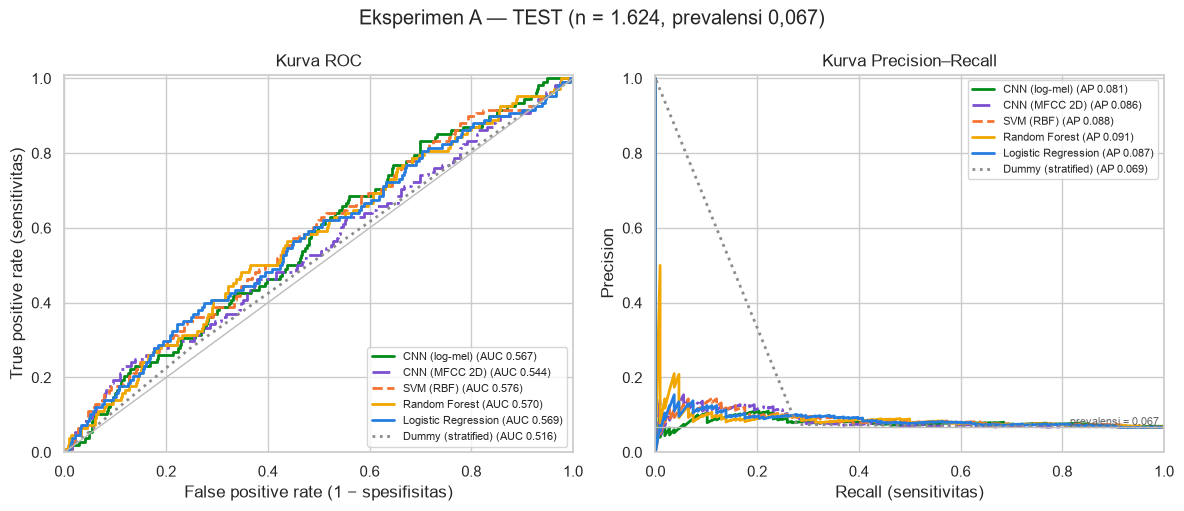

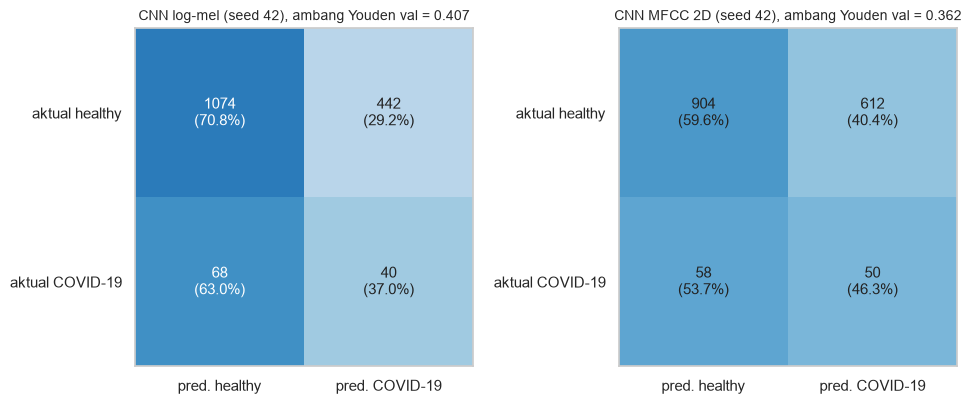

In [9]:
pm = pd.read_parquet(M / 'preds_ml_A.parquet')
te = pm[pm.split == 'test'].merge(pc[pc.split == 'test'], on=['uuid', 'label', 'split'])
assert len(te) == 1624
scores = {'CNN (log-mel)': te.cnn_logmel_s42, 'CNN (MFCC 2D)': te.cnn_mfcc2d_s42, 'SVM (RBF)': te.svm,
          'Random Forest': te.rf, 'Logistic Regression': te.logreg, 'Dummy (stratified)': te.dummy}
fig = plot_roc_pr_all(te.label, scores, 'Eksperimen A — TEST (n = 1.624, prevalensi 0,067)')
save_fig(fig, '05_roc_pr_A'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, f in zip(axes, FITUR):
    ck = CK[(f, 42)]
    cm = ev.confusion(te.label, te[f'cnn_{f}_s42'], ck['threshold'])
    plot_confusion(cm, f"CNN {FITUR[f]} (seed 42), ambang Youden val = {ck['threshold']:.3f}", ax=ax)
fig.tight_layout(); save_fig(fig, '05_confusion_A'); plt.show()

In [10]:
pairs = [('CNN (log-mel)', 'SVM (RBF)'), ('CNN (MFCC 2D)', 'SVM (RBF)'), ('CNN (log-mel)', 'CNN (MFCC 2D)'),
         ('CNN (log-mel)', 'Random Forest')]
uji = pd.DataFrame([{'model_A': a, 'model_B': b, **ev.paired_bootstrap_auc_diff(te.label, scores[a], scores[b])}
                    for a, b in pairs])
save_table(uji, '05_uji_selisih_auc', index=False)
print('Selisih AUC test (A − B), bootstrap berpasangan 2000×:'); display(uji)

Selisih AUC test (A − B), bootstrap berpasangan 2000×:


,model_A,model_B,diff,ci_low,ci_high,p
0,CNN (log-mel),SVM (RBF),-0.009,-0.058,0.038,0.719
1,CNN (MFCC 2D),SVM (RBF),-0.032,-0.101,0.040,0.402
2,CNN (log-mel),CNN (MFCC 2D),0.023,-0.047,0.095,0.534
3,CNN (log-mel),Random Forest,-0.003,-0.052,0.043,0.875


## 6. Grad-CAM: area spectrogram yang diperhatikan model
Grad-CAM (Selvaraju dkk., 2017) pada blok konvolusi terakhir CNN log-mel seed 42, input rekaman test penuh.
Per kelas: 1 contoh benar dengan keyakinan tertinggi + 1 contoh acak (seed 42) — agar tidak hanya menampilkan
contoh yang "cantik". Warna terang = area yang paling menaikkan logit COVID-19. Garis hijau = akhir area suara.

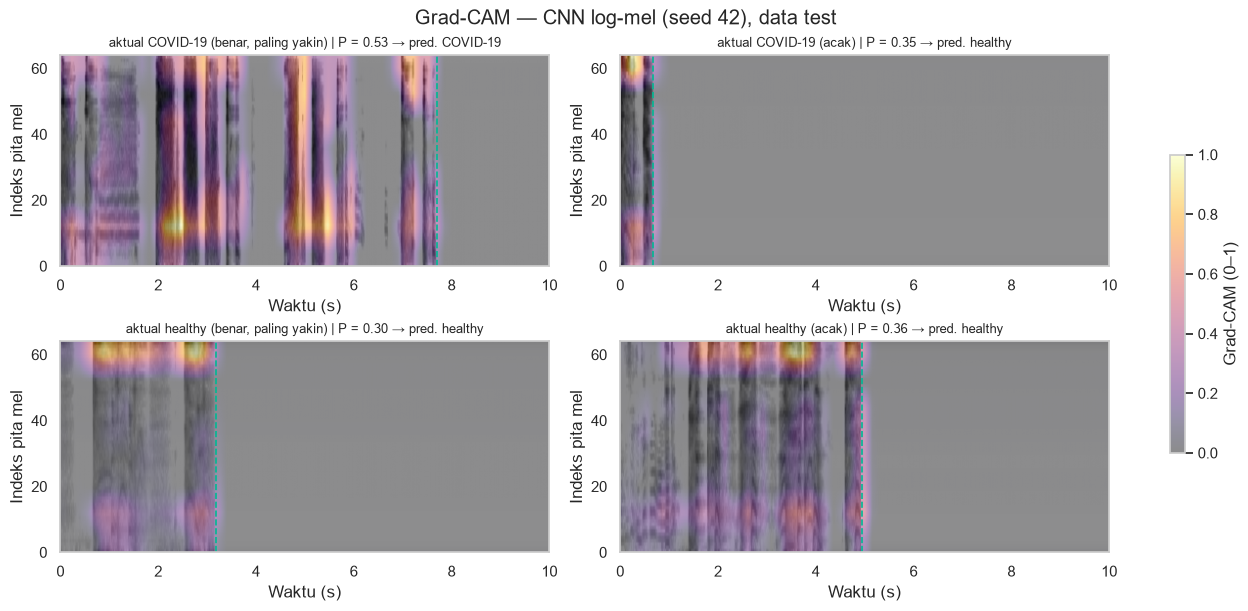

In [11]:
Xte, yte, ute, Lte = mc.load_split('logmel', 'A', 'test', 2)
ck = CK[('logmel', 42)]
Xte = ((Xte.astype(np.float32) - ck['normalizer']['mean']) / ck['normalizer']['std'])
net = mc.build_model(ck['config']); net.load_state_dict(ck['model']); net.eval()
p42 = te.set_index('uuid').loc[ute, 'cnn_logmel_s42'].values
thr = ck['threshold']; rng = np.random.default_rng(42)
pilih = []
for kelas, nama in [(1, 'COVID-19'), (0, 'healthy')]:
    idx_k = np.flatnonzero(yte == kelas)
    benar = idx_k[(p42[idx_k] >= thr) == bool(kelas)]
    yakin = benar[np.argmax(p42[benar])] if kelas else benar[np.argmin(p42[benar])]
    acak = rng.choice(np.setdiff1d(idx_k, [yakin]))
    pilih += [(yakin, nama, 'benar, paling yakin'), (acak, nama, 'acak')]
items = []
for i, nama, ket in pilih:
    cam, p = mc.grad_cam(net, torch.from_numpy(Xte[i][None, None]))
    pred = 'COVID-19' if p >= thr else 'healthy'
    items.append(dict(spec=Xte[i], cam=cam, length_s=Lte[i] * 0.02,
                      title=f'aktual {nama} ({ket}) | P = {p:.2f} → pred. {pred}'))
fig = plot_gradcam_grid(items)
fig.suptitle('Grad-CAM — CNN log-mel (seed 42), data test')
save_fig(fig, '05_gradcam'); plt.show()

**Ringkasan Grad-CAM pada banyak rekaman.** Untuk maks. 150 rekaman test per kelas (acak, seed 42; COVID-19 hanya 108 → semua): profil rata-rata
CAM per pita mel (di area suara), dan proporsi "massa" CAM yang jatuh di area *padding* dibandingkan proporsi
luas *padding* itu sendiri — bila model memakai *padding*/durasi sebagai jalan pintas, proporsi massa CAM di
*padding* akan jauh di atas proporsi luasnya.

,porsi_massa_cam_padding,porsi_luas_padding
kelas,,
COVID-19,0.040,0.568
healthy,0.046,0.593


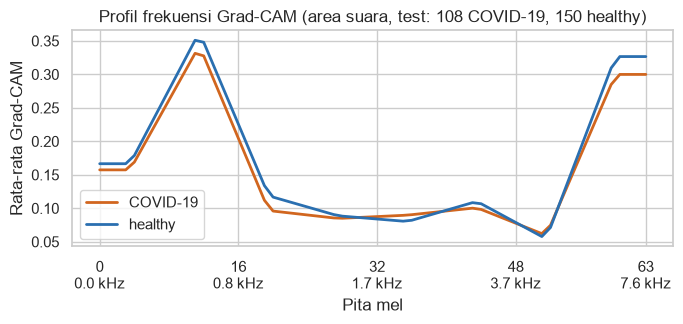

In [12]:
prof, rows = {}, []
for kelas, nama in [(1, 'COVID-19'), (0, 'healthy')]:
    pool = np.flatnonzero(yte == kelas)
    idx_k = rng.choice(pool, min(150, len(pool)), replace=False)
    acc = []
    for i in idx_k:
        cam, p = mc.grad_cam(net, torch.from_numpy(Xte[i][None, None]))
        L = int(min(Lte[i], cam.shape[1]))
        acc.append(cam[:, :L].mean(1))
        tot = cam.sum() + 1e-8
        rows.append({'kelas': nama, 'porsi_massa_cam_padding': cam[:, L:].sum() / tot,
                     'porsi_luas_padding': 1 - L / cam.shape[1]})
    prof[nama] = np.mean(acc, 0)
pad = pd.DataFrame(rows).groupby('kelas').mean()
save_table(pad.reset_index(), '05_gradcam_padding', index=False); display(pad)
from src.plots import WARNA_KELAS
fig, ax = plt.subplots(figsize=(7, 3.4))
for nama, v in prof.items():
    ax.plot(np.arange(64), v, color=WARNA_KELAS[nama], lw=2, label=nama)
import librosa
hz = librosa.mel_frequencies(66, fmin=0, fmax=8000)[1:-1]
tk = [0, 16, 32, 48, 63]
ax.set_xticks(tk, [f'{i}\n{hz[i]/1000:.1f} kHz' for i in tk])
ax.set(xlabel='Pita mel', ylabel='Rata-rata Grad-CAM', title='Profil frekuensi Grad-CAM (area suara, test: 108 COVID-19, 150 healthy)')
ax.legend(); fig.tight_layout(); save_fig(fig, '05_gradcam_profil_frekuensi'); plt.show()

## 7. Perbandingan dengan model ML klasik (Tahap 4)
Semua angka TEST, ambang Youden dari val, dari `reports/tables/hasil_semua_model.csv`. Untuk CNN, baris = seed 42;
kolom `cnn_seed_auc_*` = mean ± std AUC test 3 seed.

In [13]:
res = ev.load_results('A')
k = ['model', 'imbalance', 'val_auc', 'roc_auc', 'roc_auc_ci_low', 'roc_auc_ci_high', 'pr_auc',
     'recall_sensitivity', 'specificity', 'precision', 'f1', 'cnn_seed_auc_mean', 'cnn_seed_auc_std']
tabel = res[res.split == 'test'][k].sort_values('val_auc', ascending=False)
save_table(tabel, '05_perbandingan_model_A', index=False)
display(tabel)

,model,imbalance,val_auc,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,recall_sensitivity,specificity,precision,f1,cnn_seed_auc_mean,cnn_seed_auc_std
7,CNN (MFCC 2D),pos_weight,0.580,0.544,0.487,0.601,0.086,0.463,0.596,0.076,0.130,0.579,0.030
2,SVM (RBF),balanced,0.574,0.576,0.523,0.629,0.088,0.556,0.553,0.081,0.142,NaN,NaN
6,CNN (log-mel),pos_weight,0.566,0.567,0.511,0.619,0.081,0.370,0.708,0.083,0.136,0.572,0.006
1,Logistic Regression,balanced,0.561,0.569,0.514,0.623,0.087,0.481,0.600,0.079,0.136,NaN,NaN
5,XGBoost,balanced,0.546,0.572,0.513,0.629,0.097,0.630,0.433,0.073,0.131,NaN,NaN
3,k-NN,none,0.542,0.580,0.525,0.636,0.088,0.509,0.613,0.086,0.147,NaN,NaN
4,Random Forest,balanced,0.527,0.570,0.513,0.628,0.091,0.407,0.705,0.090,0.147,NaN,NaN
0,Dummy (stratified),none,0.476,0.516,0.472,0.563,0.069,1.000,0.000,0.067,0.125,NaN,NaN


## 8. Ringkasan
1. **CNN ringan tidak lebih baik dari ML klasik pada Eksperimen A.** AUC test (mean ± std, 3 seed): log-mel
   **0,572 ± 0,006**, MFCC 2D **0,579 ± 0,030**, sedangkan SVM RBF (fitur tabular) 0,576. Selisih AUC CNN − SVM
   pada test (seed 42; bootstrap berpasangan) −0,009 (log-mel, p = 0,72) dan −0,032 (MFCC, p = 0,40). CI selisih
   memuat 0 → **tidak berbeda bermakna**. PR-AUC ≈ 0,08–0,09 (prevalensi 0,067), precision ≈ 0,08 → tidak layak
   untuk skrining.
2. **Log-mel vs MFCC 2D:** MFCC 2D sedikit lebih tinggi rata-ratanya (val 0,586 vs 0,565), tetapi jauh lebih bervariasi
   antar-seed (test 0,544–0,601), sedangkan log-mel stabil (0,567–0,579). Selisih log-mel − MFCC seed 42 = +0,023, p = 0,53.
   *Ensemble* rata-rata 3 seed: log-mel 0,576, MFCC 0,591 (informasi tambahan, bukan model utama).
3. **Overfitting:** ringan pada log-mel (AUC train teraugmentasi − val pada checkpoint ≈ 0,02–0,06, berhenti di
   epoch 19–47) dan meningkat pada MFCC 2D (selisih 0,07–0,12; AUC train naik ke 0,71–0,72 sementara val
   mendatar di ±0,58). *Early stopping* pada AUC val + augmentasi menahannya, tetapi sinyal di label self-reported
   terlalu lemah untuk dipelajari lebih jauh. Val loss berfluktuasi besar karena hanya 108 positif.
4. **Grad-CAM:** model memperhatikan segmen batuk (ledakan energi broadband), terutama pita mel rendah (puncak ±0,5 kHz,
   rentang ±0,2–1 kHz) dan pita atas (> 5,5 kHz). Profil frekuensinya **hampir identik untuk kedua kelas** → model
   melihat bagian yang sama, hanya bobot buktinya sedikit berbeda (resolusi peta kasar: 4 × 32 sel sebelum interpolasi).
   Massa CAM di area *padding* hanya ±4% (padahal luasnya ±57%) → model **tidak** memakai *padding*/durasi sebagai
   jalan pintas. Skor probabilitas log-mel sangat sempit (90% rekaman test di 0,34–0,52; MFCC sedikit lebih lebar)
   → keyakinan rendah, sesuai AUC yang rendah; ambang Youden (0,36–0,47) wajib dipilih di val.
5. Biaya: ±97 ribu parameter, ±8–20 menit per run di CPU (6 core), total 73 menit untuk 6 run.
6. Kesimpulan untuk laporan: dengan label *self-reported* (Eksperimen A), representasi yang lebih kaya (spectrogram
   2D + CNN) **tidak menembus batas ±0,58 AUC** → faktor pembatas adalah kualitas label, bukan model/fitur
   (konsisten dengan Tahap 4 dan R4).